## Цель ноутбука

Быстро сравнить несколько моделей с базовыми настройками и проверить подозрение к `quartile_zone`. Для временного сравнения использую пять фолдов `TimeSeriesSplit`, а качество смотрю по MAE, RMSE и R². Сначала оцениваю все модели с `quartile_zone`, затем повторяю сравнение без него.

In [1]:
#автоматическая перезагрузка измененных модулей
%load_ext autoreload
%autoreload 2

## 1. Данные и цель

Здесь быстро сравню четыре модели из коробки и отдельно проверю подозрение к `quartile_zone`. В `df_train.csv` 13 603 строки и 14 столбцов, целевая переменная `price`, дата продажи `date`. Сравниваю LinearRegression, дерево решений, случайный лес и LightGBM по средним MAE, RMSE и R² на пяти фолдах.

In [2]:
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display
from side_lib import *
from visual import *
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
from lightgbm import LGBMRegressor


pd.set_option('display.float_format', '{:,.2f}'.format) 

In [3]:
data = pd.read_csv('df_train.csv')

## 2. Препроцессинг

Привожу `date` к типу даты и проверяю пропуски и полные дубликаты. Даты понадобятся для хронологической сортировки перед временным разбиением.

In [4]:
#создаем копию для предобработки
df_preprocessed = data.copy()  

In [5]:
#изменим формат даты
df_preprocessed['date'] = pd.to_datetime(df_preprocessed['date'], format='%Y-%m-%d')

In [6]:
#выведем информацию о дубликатах
mis_dup_info(df_preprocessed)

,total,missing,percent_missing,duplicated,percent_duplicated
date,13603,0,0.0%,2,0.015%
price,13603,0,0.0%,2,0.015%
bedrooms,13603,0,0.0%,2,0.015%
grade,13603,0,0.0%,2,0.015%
has_basement,13603,0,0.0%,2,0.015%
living_in_m2,13603,0,0.0%,2,0.015%
renovated,13603,0,0.0%,2,0.015%
nice_view,13603,0,0.0%,2,0.015%
perfect_condition,13603,0,0.0%,2,0.015%
real_bathrooms,13603,0,0.0%,2,0.015%


В таблице видно 2 полных дубликата. Удаляю их и сортирую строки по `date`, чтобы последующие тестовые фолды шли позже обучающих.

In [7]:
df_preprocessed = (
    df_preprocessed.drop_duplicates()
    .sort_values('date')
    .reset_index(drop=True)
)

Булевы признаки перевожу в числа 0 и 1. Так все модели получают их в одном понятном числовом виде.

In [8]:
#преобразуем булевы признаки в числовые
bool_cols = ['has_basement', 'nice_view', 'perfect_condition', 'has_lavatory', 'single_floor', 'renovated']
for col in bool_cols:
    df_preprocessed[col] = df_preprocessed[col].astype(int)


In [9]:
#выведем информацию о датафрейме после предобработки
df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13601 entries, 0 to 13600
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               13601 non-null  datetime64[ns]
 1   price              13601 non-null  float64       
 2   bedrooms           13601 non-null  int64         
 3   grade              13601 non-null  int64         
 4   has_basement       13601 non-null  int64         
 5   living_in_m2       13601 non-null  float64       
 6   renovated          13601 non-null  int64         
 7   nice_view          13601 non-null  int64         
 8   perfect_condition  13601 non-null  int64         
 9   real_bathrooms     13601 non-null  int64         
 10  has_lavatory       13601 non-null  int64         
 11  single_floor       13601 non-null  int64         
 12  month              13601 non-null  int64         
 13  quartile_zone      13601 non-null  int64         
dtypes: dat

Отделяю `price` от признаков, а `date` не передаю в модели. В первом сравнении `quartile_zone` остаётся среди признаков; ниже отдельно сравню результаты с ним и без него.

In [10]:
#целевой признак
X = df_preprocessed.drop(columns=['price', 'date'])
y = df_preprocessed['price']

## 3. Pipeline

Оборачиваю каждую модель в `Pipeline`, чтобы одинаково запускать обучение по фолдам. Здесь модели работают с текущими числовыми столбцами без подбора параметров.

In [11]:
pipelines = {
    #Линейная регрессия
    'LinearRegression': Pipeline([
        ('model', LinearRegression())
    ]),
    #Дерево решений 
    'DecisionTree': Pipeline([
        ('model', DecisionTreeRegressor(random_state=42))
    ]),
    #Случайный лес
    'RandomForest': Pipeline([
        ('model', RandomForestRegressor(n_estimators=100, random_state=42))
    ]),
    #LightGBM
    'LightGBM': Pipeline([
        ('model', LGBMRegressor(n_estimators=100, random_state=42))
    ])
}


## 4. Временные фолды

Использую `TimeSeriesSplit`, потому что строки отсортированы по дате продажи. Случайный сплит мог бы поместить более поздние продажи в обучение, когда модель проверяется на более раннем периоде.

In [12]:
tscv = TimeSeriesSplit(n_splits=5)

#вывод индексов для каждого фолда
for fold, (train_index, test_index) in enumerate(tscv.split(X)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    print(f'Fold {fold}:')
    print(f'Train: {train_index[0]}-{train_index[-1]}')
    print(f'Test:  {test_index[0]}-{test_index[-1]}')

Fold 0:
Train: 0-2270
Test:  2271-4536
Fold 1:
Train: 0-4536
Test:  4537-6802
Fold 2:
Train: 0-6802
Test:  6803-9068
Fold 3:
Train: 0-9068
Test:  9069-11334
Fold 4:
Train: 0-11334
Test:  11335-13600


После сортировки фолды идут по хронологии: обучение использует более ранние строки, проверка следующие. Разбиение сделано по строкам, а не по уникальным датам, поэтому продажи одного дня могут оказаться по разные стороны границы.

## 5. Обучение моделей

Сравниваю LinearRegression, DecisionTree, RandomForest и LightGBM с базовыми настройками. Для всех вариантов считаю MAE, RMSE и R² отдельно по каждому фолду и затем усредняю.

Сначала модели получают `quartile_zone`. Признак подозрителен, потому что связан с ценовым рейтингом зоны; сравнение с вариантом без него покажет, насколько сильно меняются метрики, но само по себе не установит, как именно признак рассчитывали.

In [13]:
results_with_q = {}
results_no_q = {}

### 5.1 LinearRegression с `quartile_zone`

,mean_mae,r2_mean,rmse_mean
LinearRegression,"79,290.92",0.74,"105,901.41"


,fold,mae,r2,rmse
0,0,"81,259.87",0.74,"105,097.09"
1,1,"77,134.02",0.74,"103,202.29"
2,2,"76,095.76",0.75,"102,430.62"
3,3,"77,438.29",0.75,"104,232.77"
4,4,"84,526.63",0.70,"114,544.29"


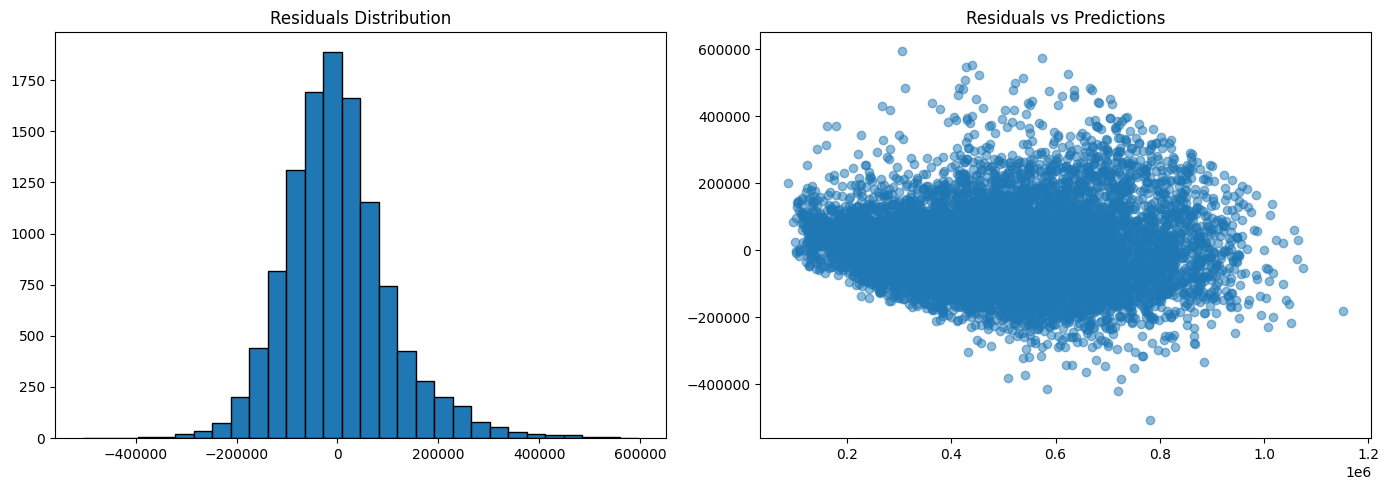

Feature importance недоступна для этой модели


In [14]:
df_res_lr_mean, df_res_lr_folds = evaluate_pipeline_to_df(
    "LinearRegression", pipelines['LinearRegression'], X, y, tscv
)

#сохраняем результаты для дальнейшего сравнения
results_with_q["LinearRegression"] = df_res_lr_mean

Средние метрики по пяти фолдам: MAE 79 291, RMSE 105 901, R² **0.74**. Между фолдами MAE был 76 096–84 527, RMSE 102 431–114 544, R² **0.70–0.75**; это сильный ориентир для остальных моделей с признаком.

### 5.2 DecisionTree с `quartile_zone`

,mean_mae,r2_mean,rmse_mean
DecisionTree,"105,097.91",0.51,"143,982.57"


,fold,mae,r2,rmse
0,0,"103,538.00",0.53,"141,497.01"
1,1,"105,010.72",0.50,"144,467.73"
2,2,"102,965.95",0.51,"142,594.13"
3,3,"106,382.88",0.51,"146,072.76"
4,4,"107,592.00",0.52,"145,281.23"


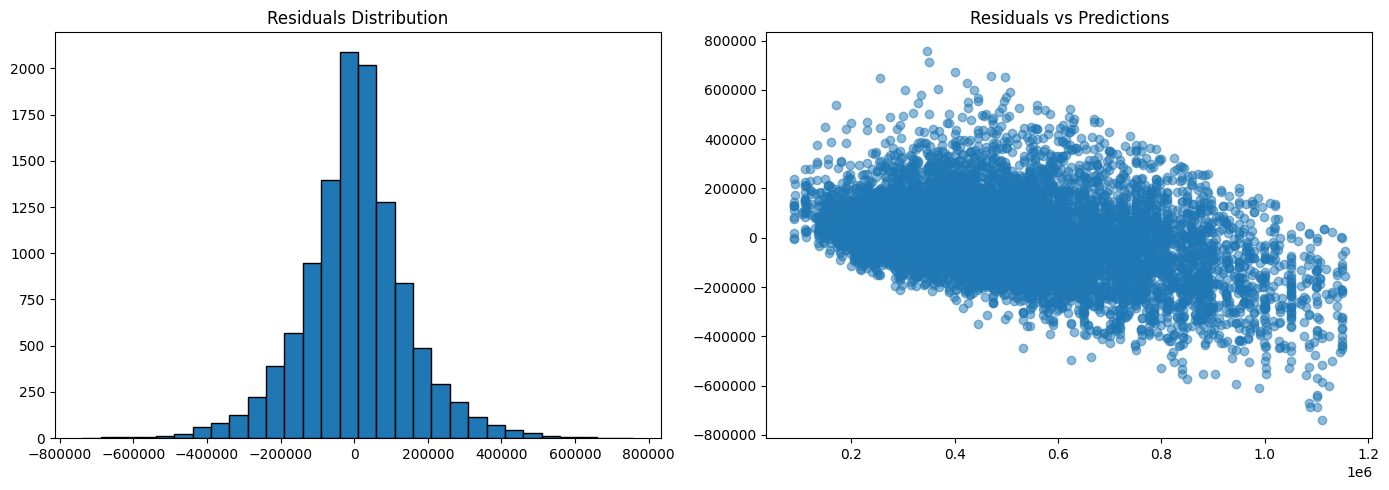

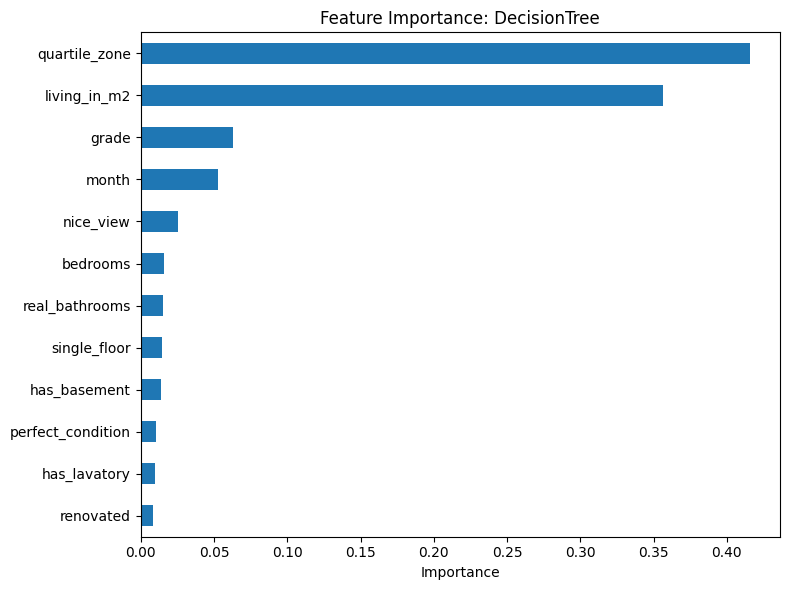

In [15]:
df_res_dt_mean, df_res_dt_folds = evaluate_pipeline_to_df(
    "DecisionTree",
    pipelines['DecisionTree'],
    X, y,
    tscv,
    plot_residuals=True
)

results_with_q["DecisionTree"] = df_res_dt_mean

Средние метрики по пяти фолдам: MAE 105 098, RMSE 143 983, R² **0.51**. По фолдам MAE менялся от 102 966 до 107 592, RMSE от 141 497 до 146 073, R² от **0.50** до **0.53**; дерево уступает LinearRegression.

### 5.3 RandomForest с `quartile_zone`

,mean_mae,r2_mean,rmse_mean
RandomForest,"78,502.62",0.73,"107,623.42"


,fold,mae,r2,rmse
0,0,"78,269.44",0.74,"106,143.29"
1,1,"77,309.11",0.73,"105,612.09"
2,2,"74,823.27",0.75,"102,995.22"
3,3,"79,046.29",0.72,"109,466.65"
4,4,"83,065.01",0.70,"113,899.87"


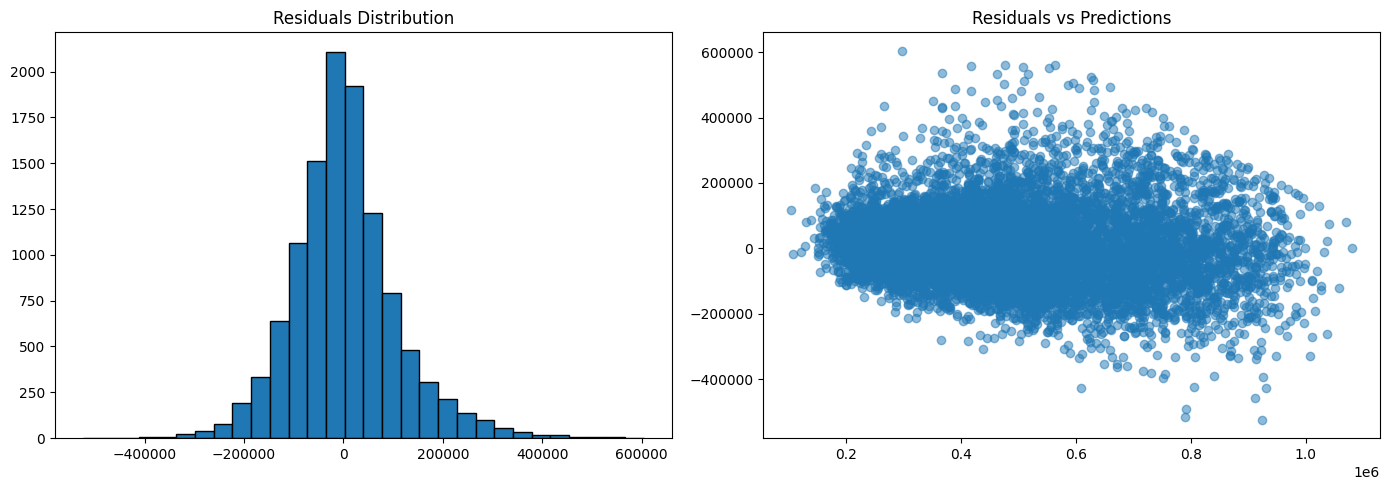

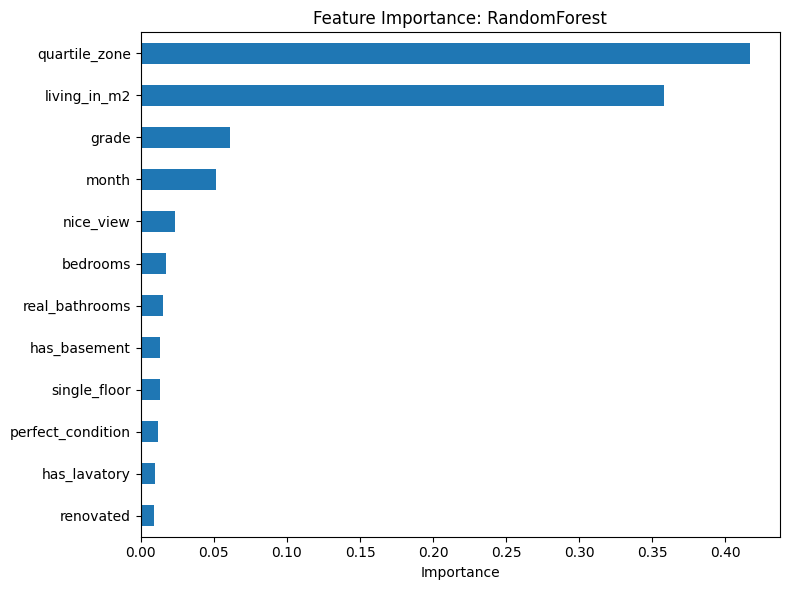

In [16]:
df_res_rf_mean, df_res_rf_folds = evaluate_pipeline_to_df(
    "RandomForest", pipelines['RandomForest'], X, y, tscv
)

results_with_q["RandomForest"] = df_res_rf_mean

Средние метрики по пяти фолдам: MAE 78 503, RMSE 107 623, R² **0.73**. По фолдам MAE был 74 823–83 065, RMSE 102 995–113 900, R² **0.70–0.75**; средний R² близок к LinearRegression.

### 5.4 LightGBM с `quartile_zone`

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000796 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 287
[LightGBM] [Info] Number of data points in the train set: 2271, number of used features: 12
[LightGBM] [Info] Start training from score 487156.188023


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000256 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 291
[LightGBM] [Info] Number of data points in the train set: 4537, number of used features: 12
[LightGBM] [Info] Start training from score 481968.043200
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000247 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 293
[LightGBM] [Info] Number of data points in the train set: 6803, number of used features: 12
[LightGBM] [Info] Start training from score 479514.051595


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000463 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 295
[LightGBM] [Info] Number of data points in the train set: 9069, number of used features: 12
[LightGBM] [Info] Start training from score 475151.774286
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000665 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 298
[LightGBM] [Info] Number of data points in the train set: 11335, number of used features: 12


[LightGBM] [Info] Start training from score 472652.572298


,mean_mae,r2_mean,rmse_mean
LightGBM,"74,753.35",0.75,"102,409.25"


,fold,mae,r2,rmse
0,0,"75,293.14",0.76,"102,206.00"
1,1,"72,632.01",0.76,"100,073.17"
2,2,"72,309.27",0.77,"98,775.00"
3,3,"73,610.08",0.76,"101,704.16"
4,4,"79,922.27",0.73,"109,287.93"


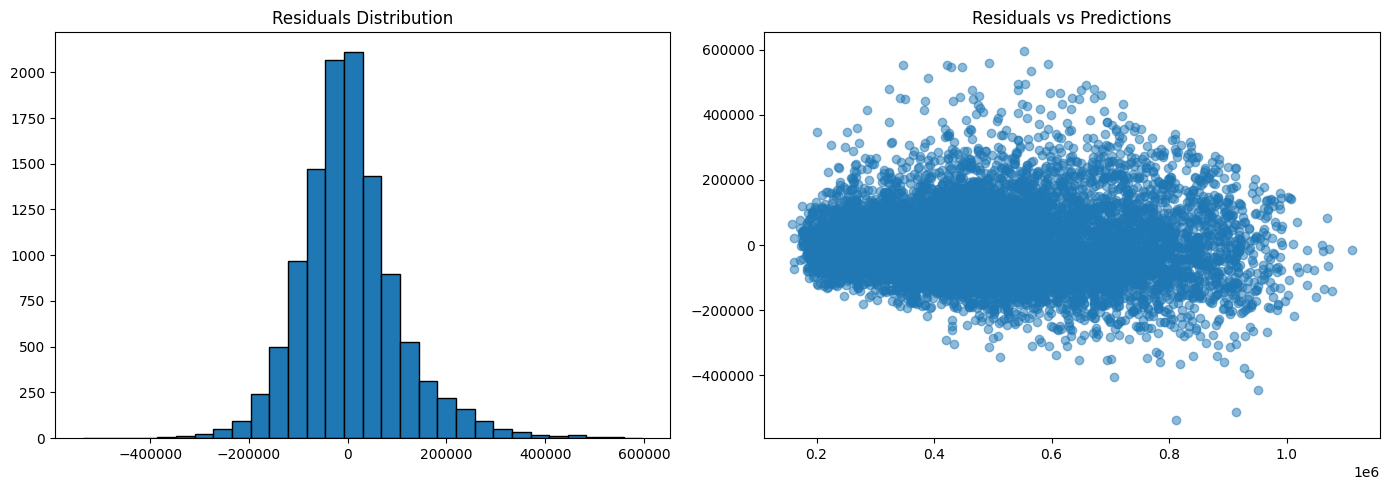

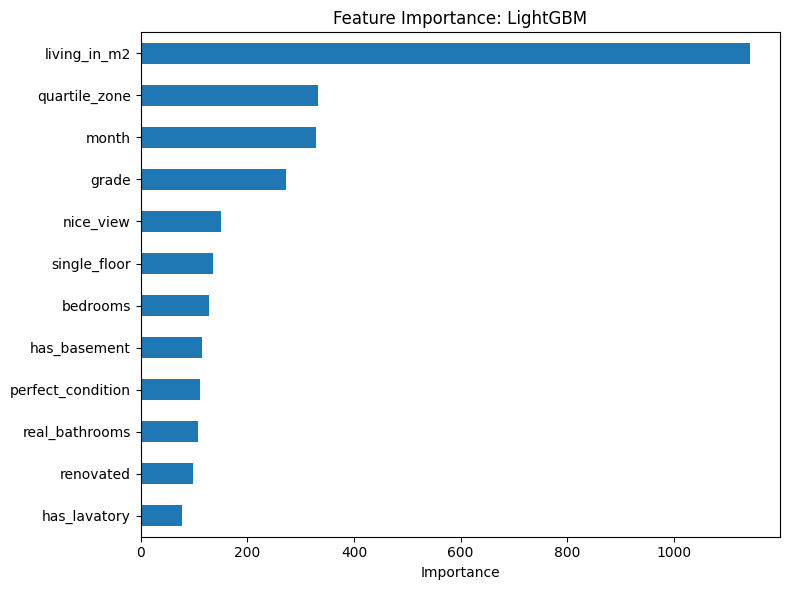

In [17]:
df_res_gb_mean, df_res_gb_folds = evaluate_pipeline_to_df(
    "LightGBM", pipelines['LightGBM'], X, y, tscv
)

results_with_q["LightGBM"] = df_res_gb_mean

Средние метрики по пяти фолдам: MAE 74 753, RMSE 102 409, R² **0.75**. По фолдам MAE менялся от 72 309 до 79 922, RMSE от 98 775 до 109 288, R² от **0.73** до **0.77**; это лучший средний результат с `quartile_zone`.

## 6. Проверка `quartile_zone`

Теперь повторяю те же модели и временные фолды без `quartile_zone`. Признак напрямую связан с ценой, поэтому заметное падение качества без него усилит подозрение на утечку, но не докажет её.

In [18]:
X_no_quar_zone = X.drop(columns=['quartile_zone'])

### 6.1 LinearRegression без `quartile_zone`

,mean_mae,r2_mean,rmse_mean
LinearRegression,"115,843.28",0.50,"146,604.10"


,fold,mae,r2,rmse
0,0,"115,939.41",0.52,"144,234.62"
1,1,"108,654.59",0.54,"138,660.56"
2,2,"112,854.23",0.50,"144,107.61"
3,3,"119,373.85",0.48,"149,746.74"
4,4,"122,394.32",0.44,"156,270.96"


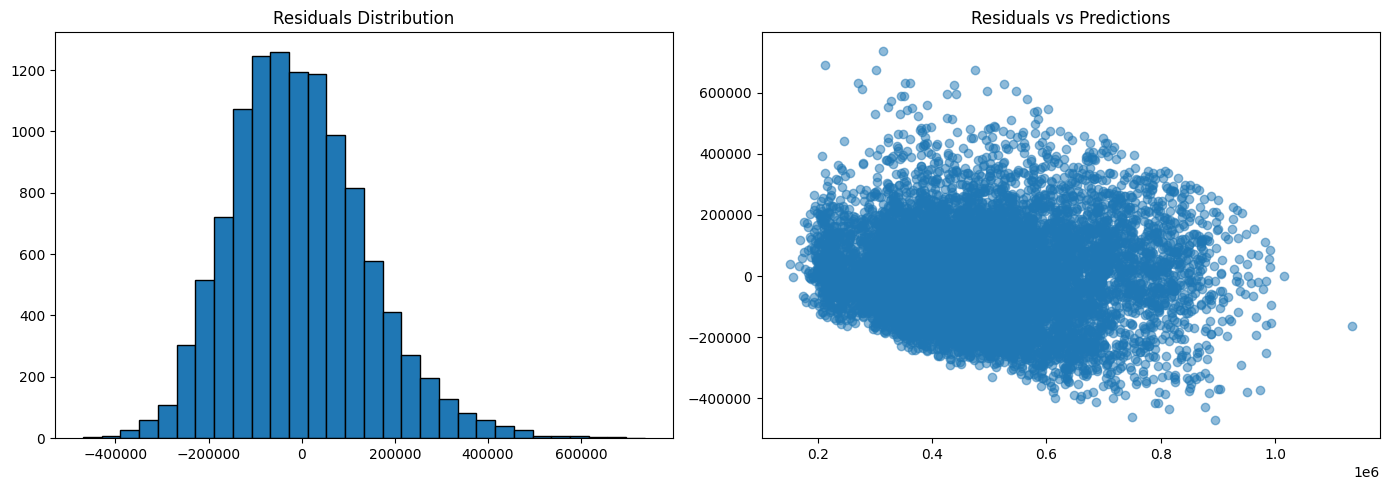

Feature importance недоступна для этой модели


In [19]:
df_res_lr_mean, df_res_lr_folds = evaluate_pipeline_to_df(
    "LinearRegression", pipelines['LinearRegression'], X_no_quar_zone, y, tscv
)

results_no_q["LinearRegression"] = df_res_lr_mean

Без `quartile_zone` средние метрики LinearRegression: MAE 115 843, RMSE 146 604, R² **0.50**. Между фолдами MAE был 108 655–122 394, RMSE 138 661–156 271, R² **0.44–0.54**; средний R² ниже **0.74** с признаком.

### 6.2 DecisionTree без `quartile_zone`

,mean_mae,r2_mean,rmse_mean
DecisionTree,"152,706.85",0.07,"199,186.58"


,fold,mae,r2,rmse
0,0,"150,101.41",0.09,"197,224.52"
1,1,"144,610.50",0.14,"189,024.07"
2,2,"151,403.96",0.05,"199,433.52"
3,3,"157,093.03",0.05,"202,890.51"
4,4,"160,325.36",0.02,"207,360.27"


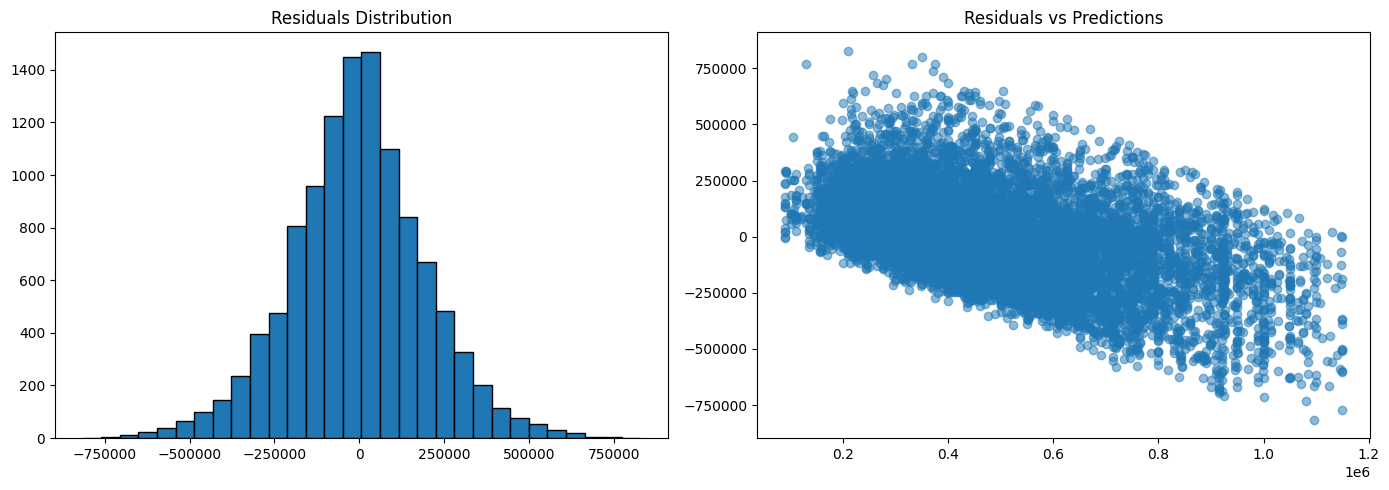

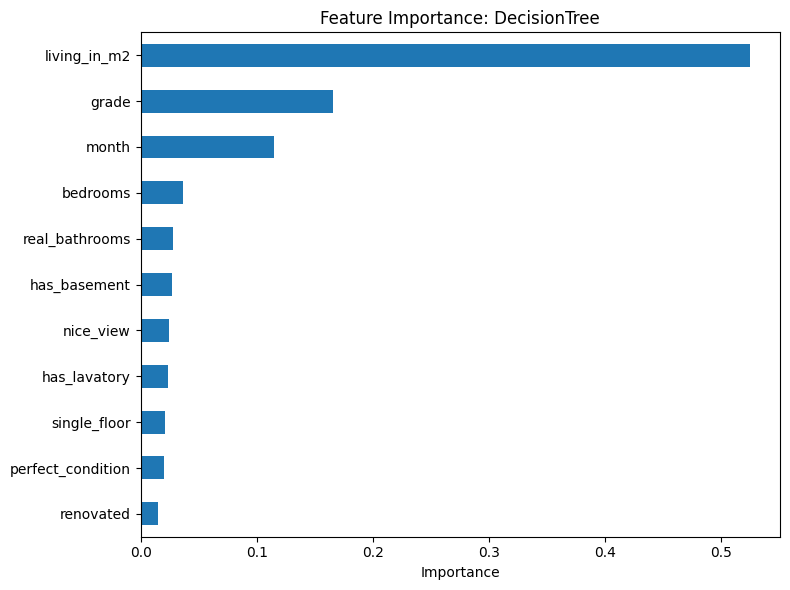

In [20]:
df_res_dt_mean, df_res_dt_folds = evaluate_pipeline_to_df(
    "DecisionTree", pipelines['DecisionTree'], X_no_quar_zone, y, tscv
)

results_no_q["DecisionTree"] = df_res_dt_mean

Без `quartile_zone` средние метрики DecisionTree: MAE 152 707, RMSE 199 187, R² **0.07**. По фолдам MAE менялся от 144 611 до 160 325, RMSE от 189 025 до 207 360, R² от **0.02** до **0.14**; это самый слабый вариант.

### 6.3 RandomForest без `quartile_zone`

,mean_mae,r2_mean,rmse_mean
RandomForest,"120,098.05",0.44,"154,384.63"


,fold,mae,r2,rmse
0,0,"118,815.47",0.47,"150,668.05"
1,1,"113,959.60",0.47,"148,506.15"
2,2,"117,292.45",0.45,"151,868.46"
3,3,"123,159.55",0.42,"157,572.06"
4,4,"127,263.16",0.39,"163,308.40"


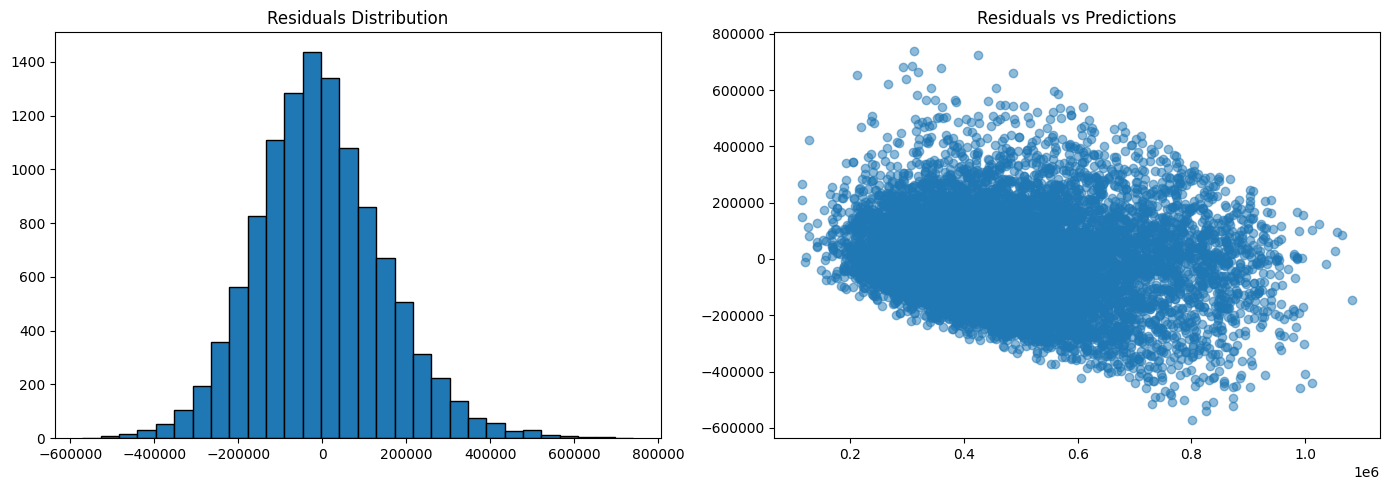

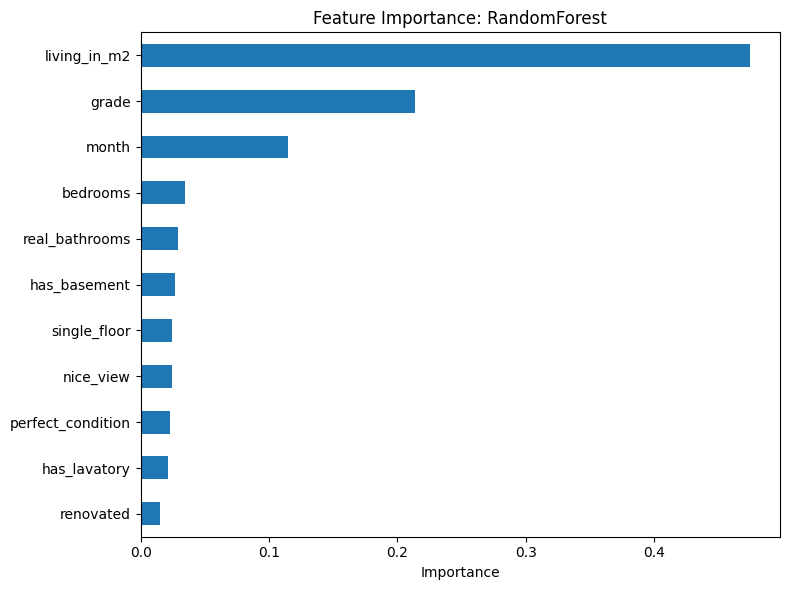

In [21]:
df_res_rf_mean, df_res_rf_folds = evaluate_pipeline_to_df(
    "RandomForest", pipelines['RandomForest'], X_no_quar_zone, y, tscv
)

results_no_q["RandomForest"] = df_res_rf_mean

Без `quartile_zone` средние метрики RandomForest: MAE 120 098, RMSE 154 385, R² **0.44**. По фолдам MAE был 113 960–127 263, RMSE 148 506–163 308, R² **0.39–0.47**.

### 6.4 LightGBM без `quartile_zone`

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000390 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 282
[LightGBM] [Info] Number of data points in the train set: 2271, number of used features: 11
[LightGBM] [Info] Start training from score 487156.188023
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000197 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 286
[LightGBM] [Info] Number of data points in the train set: 4537, number of used features: 11
[LightGBM] [Info] Start training from score 481968.043200


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000330 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 288
[LightGBM] [Info] Number of data points in the train set: 6803, number of used features: 11
[LightGBM] [Info] Start training from score 479514.051595
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000639 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 290
[LightGBM] [Info] Number of data points in the train set: 9069, number of used features: 11
[LightGBM] [Info] Start training from score 475151.774286


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000411 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 293
[LightGBM] [Info] Number of data points in the train set: 11335, number of used features: 11
[LightGBM] [Info] Start training from score 472652.572298


,mean_mae,r2_mean,rmse_mean
LightGBM,"113,078.07",0.51,"144,775.94"


,fold,mae,r2,rmse
0,0,"114,647.70",0.51,"144,870.97"
1,1,"107,393.73",0.54,"138,719.36"
2,2,"109,414.28",0.52,"141,433.09"
3,3,"114,883.43",0.50,"146,318.46"
4,4,"119,051.20",0.47,"152,537.84"


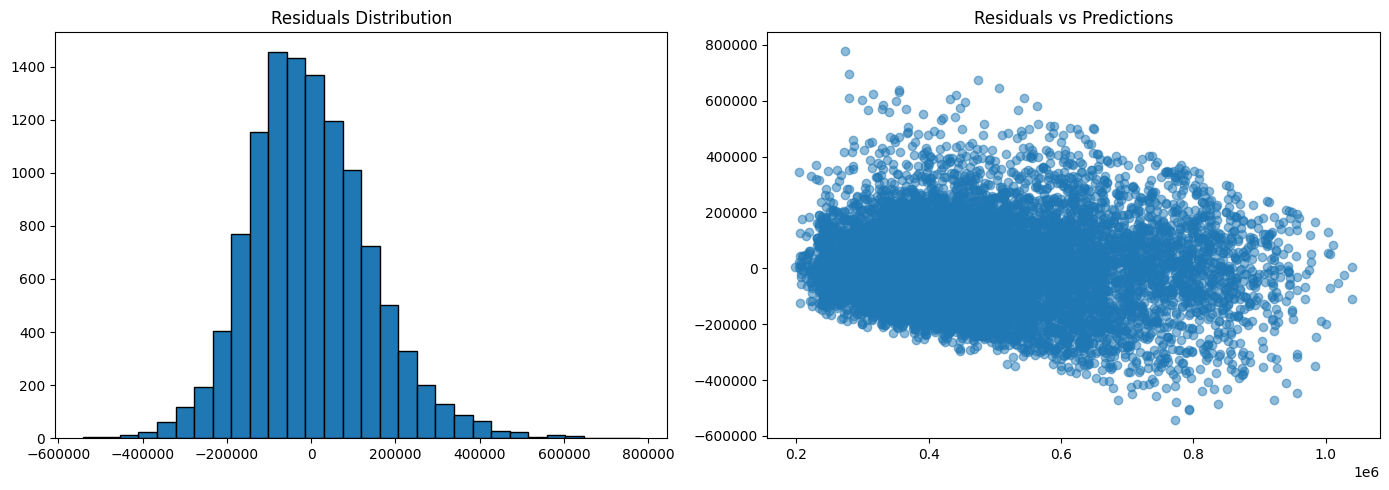

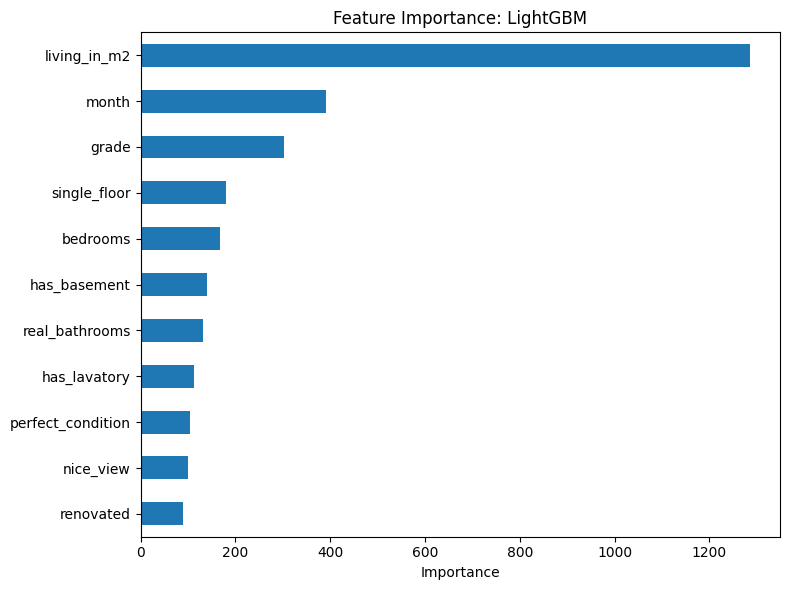

In [22]:
df_res_gbm_mean, df_res_gbm_folds = evaluate_pipeline_to_df(
    "LightGBM", pipelines['LightGBM'], X_no_quar_zone, y, tscv
)
results_no_q["LightGBM"] = df_res_gbm_mean

Без `quartile_zone` средние метрики LightGBM: MAE 113 078, RMSE 144 776, R² **0.51**. По фолдам MAE менялся от 107 394 до 119 051, RMSE от 138 719 до 152 538, R² от **0.47** до **0.54**; это лучшее среднее R² без признака.

## 7. Сводное сравнение

In [23]:
df_final_comp = pd.concat(results_with_q.values())
df_final_comp_no_q = pd.concat(results_no_q.values())

### С `quartile_zone`

Сначала сравниваю средние MAE и RMSE четырёх моделей с признаком. На графике столбцы показывают значения из таблиц выше.

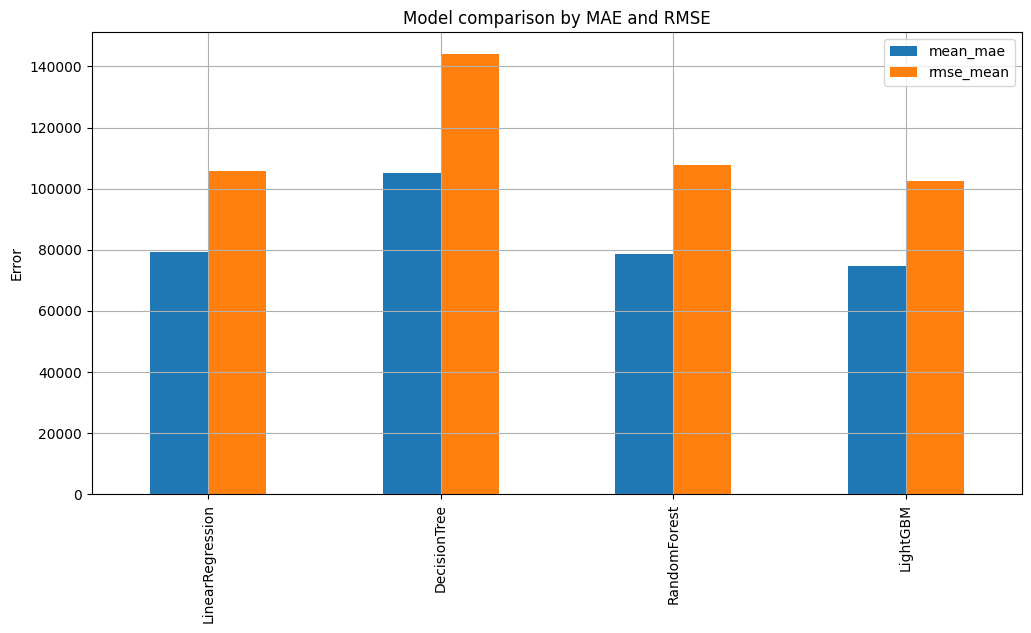

In [24]:
df_final_comp.plot(
    y=['mean_mae', 'rmse_mean'],
    kind='bar',
    figsize=(12, 6),
    grid=True,
    title='Model comparison by MAE and RMSE'
)
plt.ylabel('Error')
plt.show()


С `quartile_zone` LightGBM имеет наименьшие средние MAE (74 753) и RMSE (102 409), а также наибольший R² (**0.75**). Ближе всего к нему LinearRegression и RandomForest по R² (**0.74** и **0.73**); DecisionTree заметно слабее.

### Без `quartile_zone`

Теперь те же средние метрики сравниваются без подозрительного признака. Это более осторожный ориентир, хотя временное разбиение здесь всё ещё проходит по строкам.

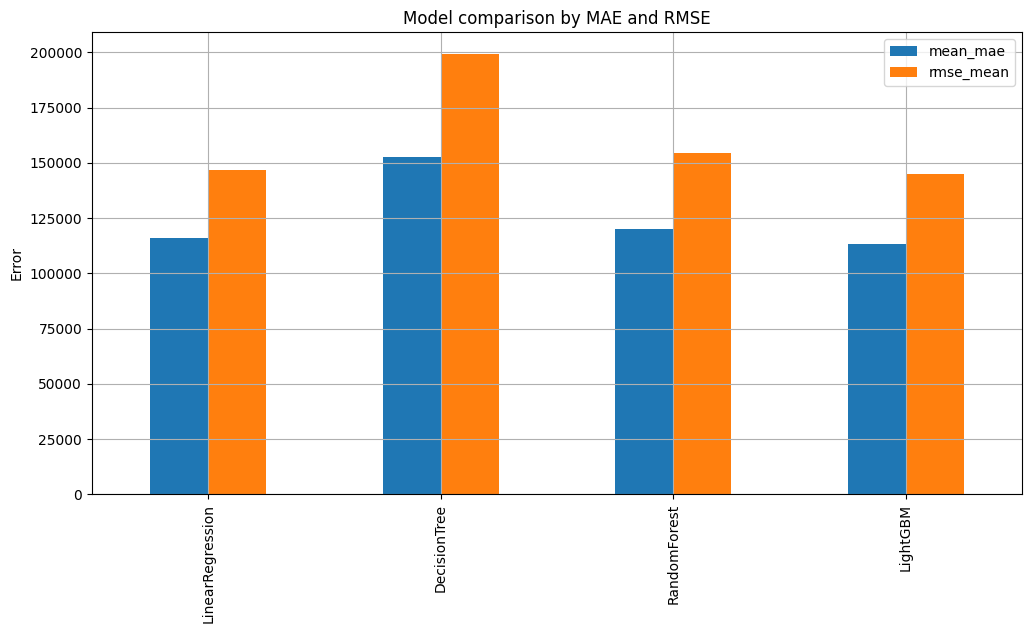

In [25]:
df_final_comp_no_q.plot(
    y=['mean_mae', 'rmse_mean'],
    kind='bar',
    figsize=(12, 6),
    grid=True,
    title='Model comparison by MAE and RMSE'
)
plt.ylabel('Error')
plt.show()


Без `quartile_zone` LightGBM показывает наименьшие средние MAE (113 078) и RMSE (144 776). У остальных моделей ошибки выше, особенно у DecisionTree.

### Изменение R² при удалении признака

Сравниваю R² для каждой модели с `quartile_zone` и без него. Таблица показывает разницу средних значений, а столбчатый график помогает сопоставить модели.

,r2_mean_no_q,r2_mean_with_q,r2_difference
LinearRegression,0.50,0.74,0.24
DecisionTree,0.07,0.51,0.44
RandomForest,0.44,0.73,0.29
LightGBM,0.51,0.75,0.25


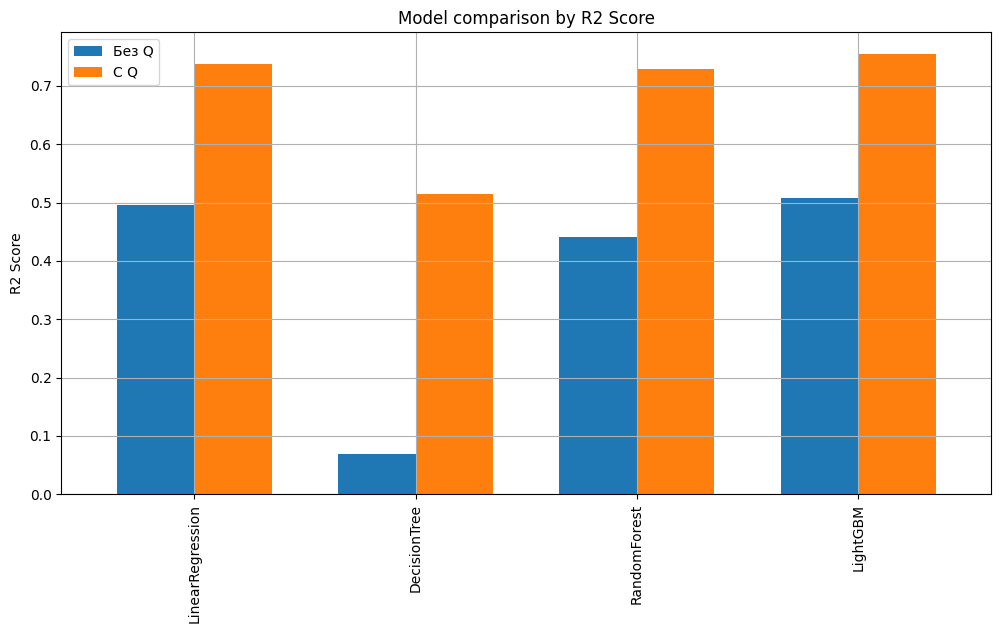

In [26]:
df_merged = df_final_comp_no_q[['r2_mean']].merge(
    df_final_comp[['r2_mean']], 
    left_index=True, 
    right_index=True, 
    suffixes=('_no_q', '_with_q') # Добавит суффиксы к названиям колонок
)

# 2. Строим график по объединенному DataFrame
df_merged.plot(
    y=['r2_mean_no_q', 'r2_mean_with_q'],
    kind='bar',
    figsize=(12, 6),
    grid=True,
    title='Model comparison by R2 Score',
    width=0.7 # Ширина пары столбцов
)

df_merged['r2_difference'] = df_merged['r2_mean_with_q'] - df_merged['r2_mean_no_q']
display(df_merged.round(3))

plt.ylabel('R2 Score')
plt.legend(['Без Q', 'С Q']) # Красивые названия для легенды
plt.show()

Сводная таблица показывает падение R² после удаления `quartile_zone`: **0.24** у LinearRegression, **0.44** у DecisionTree, **0.29** у RandomForest и **0.25** у LightGBM. Такой скачок согласуется с подозрением к связанному с ценой признаку, но сам по себе не доказывает утечку.

## 8. Выводы

С `quartile_zone` лучшим оказался LightGBM: средний R² **0.75**, MAE 74 753, RMSE 102 409. Без него лучшим остался LightGBM, но с R² **0.51**, MAE 113 078 и RMSE 144 776; падение R² по сводной таблице составляет **0.25**. Такой разрыв согласуется с подозрением к `quartile_zone`, но не доказывает утечку: способ расчёта признака здесь неизвестен.

Это предварительное сравнение: `TimeSeriesSplit` делит отсортированные строки, а не целые даты, отдельного holdout здесь нет, параметры моделей не подбирались. В `improvements.ipynb` проверяется более аккуратная временная схема и признаки без `quartile_zone`, а в `tuning.ipynb` подбираются параметры.